In [20]:
from joblib import load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from matplotlib.colors import LogNorm
from kids.catalog.preparation import load_and_prepare_training_catalog, merge_training_catalogs
from kids.catalog.features import CLF_FEATURES
from kids.ml.classification.xgbclf import XGBClf
from kids.ml.som.som import MySOM
from kids.ml.training_data import TrainingData

In [2]:
kids_x_desi = load_and_prepare_training_catalog('../data/raw_data/KiDS_DR5_WCScut_x_DESI_DR1_columns.csv')
kids_x_sdss = load_and_prepare_training_catalog('../data/raw_data/KiDS_DR5_WCScut_x_SDSS_DR17_columns.csv')
catalog = merge_training_catalogs(kids_x_desi, kids_x_sdss)
training_data = TrainingData(catalog, CLF_FEATURES, train_size=0.6)
X_test, y_test = training_data.get_test_clf()
y_test = np.asarray(y_test, dtype=int)
raw_test = training_data.data.loc[training_data.idx_test].reset_index(drop=True)
assert len(raw_test) == len(X_test) == len(y_test)

In [3]:
SOM_PATH = '../saved_models/som/som_2026-11-05T17-48-12Z.pth'
XGB_PATH = '../saved_models/classification/xgb_clf_2026-10-30T11-32-05Z.json'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SOM_CONFIG = {
    'x': 60, 'y': 60, 'num_features': len(CLF_FEATURES), 'epochs': 35,
    'batch_size': 4 * 1024, 'learning_rate': 0.8, 'sigma': 35,
    'device': DEVICE, 'topology': 'rectangular', 'pbc': True,
    'lr_decay_function': 'asymptotic_decay',
    'sigma_decay_function': 'lr_linear_decay_to_zero',
    'neighborhood_function': 'gaussian', 'distance_function': 'euclidean',
    'initialization_mode': 'pca',
}
preprocessor = load('../saved_models/som/preprocessor_2026-11-05T17-48-12Z.joblib')
som = MySOM(**SOM_CONFIG)
som.load_state_dict(torch.load(SOM_PATH, map_location=DEVICE, weights_only=True))
som.eval()
xgb_clf = XGBClf()
xgb_clf.load(XGB_PATH)
assert tuple(som.weights.shape) == (SOM_CONFIG['x'], SOM_CONFIG['y'], len(CLF_FEATURES))

In [4]:
X_som = preprocessor.transform(raw_test.loc[:, CLF_FEATURES])
with torch.no_grad():
    X_tensor = torch.as_tensor(X_som, dtype=torch.float32, device=DEVICE)
    bmus = som.identify_bmus(X_tensor).cpu().numpy()
probabilities = np.asarray(xgb_clf.model.predict_proba(X_test))
predicted = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
assert probabilities.shape == (len(y_test), len(TrainingData.CLASS_TO_ID))
assert np.isclose(probabilities.sum(axis=1), 1).all()
assert np.array_equal(predicted, np.asarray(xgb_clf.predict(X_test), dtype=int))

In [5]:
n_x, n_y = SOM_CONFIG['x'], SOM_CONFIG['y']
cell_id = bmus[:, 0] * n_y + bmus[:, 1]
classes = list(TrainingData.CLASS_TO_ID)
assignments = pd.DataFrame({
    'cell_id': cell_id, 'bmu_x': bmus[:, 0], 'bmu_y': bmus[:, 1],
    'true_class_id': y_test, 'predicted_class_id': predicted,
    'confidence': confidence, 'correct': predicted == y_test,})

In [6]:
# Calculate true class counts and QSO F1 score for every occupied cell.
assignments_per_cell = assignments.groupby(['cell_id', 'true_class_id']).size().unstack()
class_ids = TrainingData.CLASS_TO_ID
star_count_per_cell = assignments_per_cell.get(class_ids['STAR'], pd.Series(dtype=int))
galaxy_count_per_cell = assignments_per_cell.get(class_ids['GALAXY'], pd.Series(dtype=int))
qso_count_per_cell = assignments_per_cell.get(class_ids['QSO'], pd.Series(dtype=int))

qso_true = assignments['true_class_id'].eq(class_ids['QSO'])
qso_predicted = assignments['predicted_class_id'].eq(class_ids['QSO'])
qso_true_positive = (qso_true & qso_predicted).groupby(assignments['cell_id']).sum()
qso_false_positive = (~qso_true & qso_predicted).groupby(assignments['cell_id']).sum()
qso_false_negative = (qso_true & ~qso_predicted).groupby(assignments['cell_id']).sum()
qso_f1_per_cell = (2 * qso_true_positive).div(
    2 * qso_true_positive + qso_false_positive + qso_false_negative
).where(lambda values: values.notna())

In [7]:
from kids.catalog.cleaning import clean_mask, replace_sentinel
from kids.catalog.features import add_colors, add_ratios, MAGNITUDES

DATA_PATH = "../data/classification/KiDS_DR5_WCScut_columns_SPECTYPE_train_60.csv"
CHUNK_SIZE = 1_000_000
INFERENCE_BATCH_SIZE = 4 * 1024
photo_prediction_column = "PREDICTED_CLASS"
required_columns = list(dict.fromkeys(
    MAGNITUDES + ["MASK", "CLASS_STAR", photo_prediction_column]
))
dd = pd.read_csv(DATA_PATH, usecols=required_columns, chunksize=CHUNK_SIZE)

full_cell_count = np.zeros(n_x * n_y, dtype=np.int64)
full_r_mag_sum = np.zeros(n_x * n_y, dtype=np.float64)
full_r_mag_count = np.zeros(n_x * n_y, dtype=np.int64)
full_missing_magnitude_count = np.zeros(n_x * n_y, dtype=np.int64)
full_qso_photo_count = np.zeros(n_x * n_y, dtype=np.int64)
full_total_objects = 0
full_magnitude_count = len(MAGNITUDES)

In [8]:
with torch.no_grad():
    for raw_chunk in dd:
        chunk = (
            raw_chunk
            .pipe(clean_mask)
            .pipe(replace_sentinel)
            .pipe(add_colors)
            .pipe(add_ratios)
            .reset_index(drop=True)
        )
        full_total_objects += len(chunk)
        feature_data = chunk.loc[:, CLF_FEATURES]
        magnitude_data = chunk.loc[:, MAGNITUDES]
        r_mag = magnitude_data["MAG_GAAP_r"].to_numpy(dtype=np.float64)
        missing_magnitudes = magnitude_data.isna().sum(axis=1).to_numpy(dtype=np.int64)
        is_photo_qso = chunk[photo_prediction_column].eq("QSO").to_numpy()

        for start in range(0, len(feature_data), INFERENCE_BATCH_SIZE):
            stop = min(start + INFERENCE_BATCH_SIZE, len(feature_data))
            X_batch = preprocessor.transform(feature_data.iloc[start:stop])
            X_tensor = torch.as_tensor(X_batch, dtype=torch.float32, device=DEVICE)
            batch_bmus = som.identify_bmus(X_tensor).cpu().numpy()
            batch_cell_id = batch_bmus[:, 0] * n_y + batch_bmus[:, 1]
            full_cell_count += np.bincount(batch_cell_id, minlength=n_x * n_y)
            batch_r_mag = r_mag[start:stop]
            valid_r_mag = np.isfinite(batch_r_mag)
            full_r_mag_sum += np.bincount(
                batch_cell_id[valid_r_mag], weights=batch_r_mag[valid_r_mag],
                minlength=n_x * n_y,
            )
            full_r_mag_count += np.bincount(
                batch_cell_id[valid_r_mag], minlength=n_x * n_y
            )
            full_missing_magnitude_count += np.bincount(
                batch_cell_id, weights=missing_magnitudes[start:stop],
                minlength=n_x * n_y,
            ).astype(np.int64)
            full_qso_photo_count += np.bincount(
                batch_cell_id[is_photo_qso[start:stop]], minlength=n_x * n_y
            )


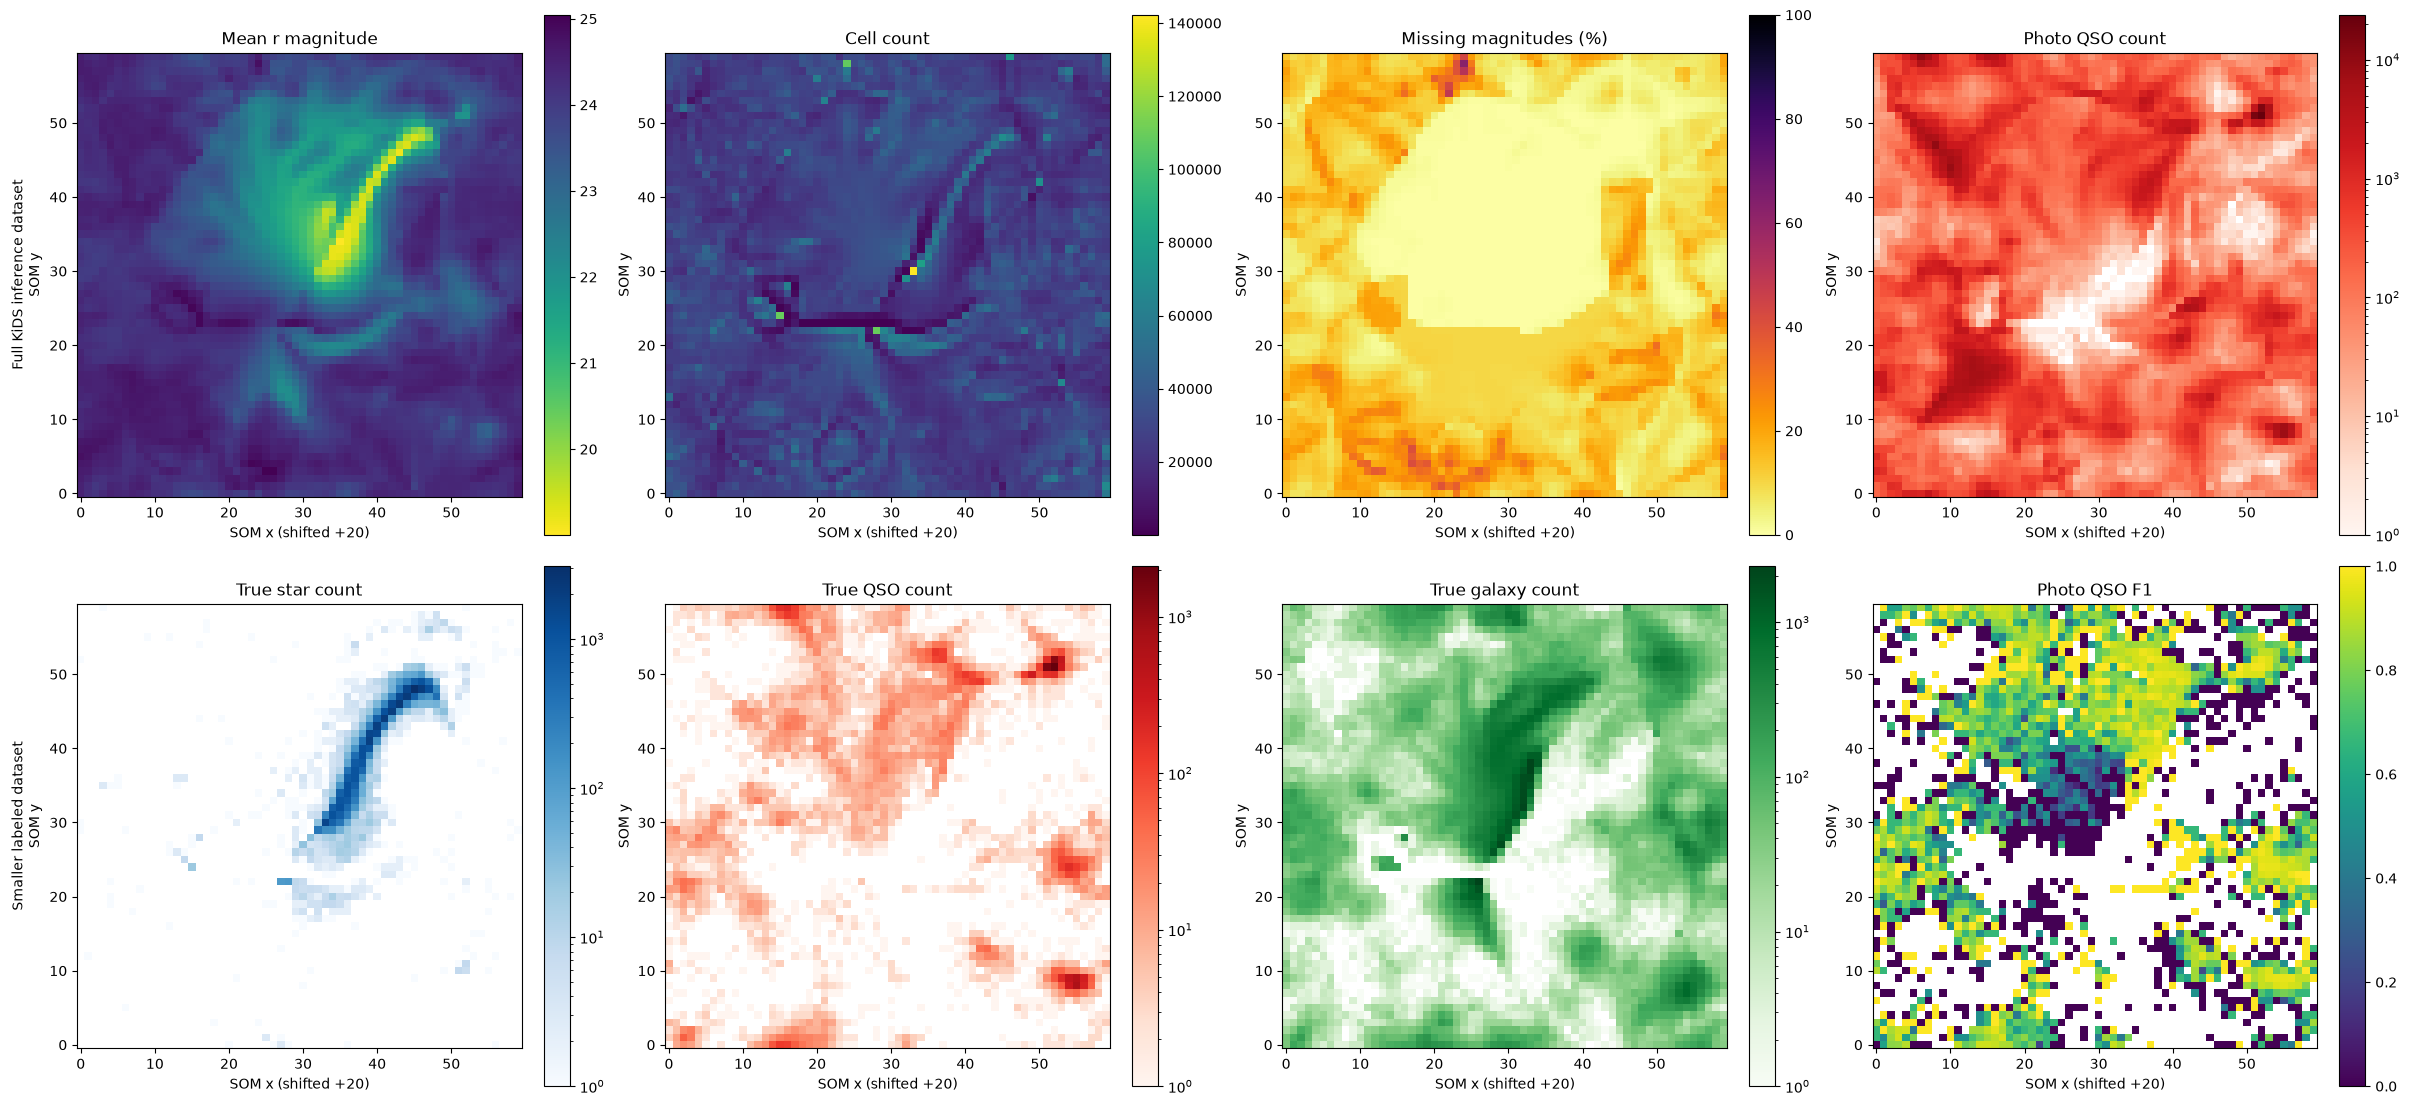

In [24]:
def som_grid(values):
    if isinstance(values, pd.Series):
        grid = np.full((n_x, n_y), np.nan, dtype=float)
        for cell_id, value in values.items():
            grid[int(cell_id) // n_y, int(cell_id) % n_y] = value
        return grid
    values = np.asarray(values)
    if values.shape != (n_x, n_y):
        raise ValueError(f'Expected a full SOM grid with shape {(n_x, n_y)}; got {values.shape}.')
    return values.copy()

full_occupied = full_cell_count > 0
full_cell_ids = np.flatnonzero(full_occupied)
full_cell_stats = pd.DataFrame({
    "cell_count": full_cell_count[full_occupied],
    "r_mag": np.divide(
        full_r_mag_sum[full_occupied], full_r_mag_count[full_occupied],
        out=np.full(full_cell_ids.size, np.nan),
        where=full_r_mag_count[full_occupied] > 0,
    ),
    "missing_magnitudes_percent": (
        100 * full_missing_magnitude_count[full_occupied]
        / (full_cell_count[full_occupied] * full_magnitude_count)
    ),
    "qso_photo_count": full_qso_photo_count[full_occupied],
    "bmu_x": full_cell_ids // n_y,
    "bmu_y": full_cell_ids % n_y,
}, index=full_cell_ids)
assert full_cell_stats["cell_count"].sum() == full_total_objects
assert full_cell_stats["missing_magnitudes_percent"].between(0, 100).all()

# Shift every displayed map right by 20 cells. This is a horizontal circular
# shift, matching the SOM's periodic boundary condition.
MAP_SHIFT = 20
full_maps = [
    (full_cell_stats["r_mag"], "Mean r magnitude", "viridis_r", None, None),
    (full_cell_stats["cell_count"], "Cell count", "viridis", None, None),
    (full_cell_stats["missing_magnitudes_percent"], "Missing magnitudes (%)", "inferno_r", 0, 100),
    (full_cell_stats["qso_photo_count"], "Photo QSO count", "Reds", None, None),
]
small_maps = [
    (star_count_per_cell, "True star count", "Blues", None, None),
    (qso_count_per_cell, "True QSO count", "Reds", None, None),
    (galaxy_count_per_cell, "True galaxy count", "Greens", None, None),
    (qso_f1_per_cell, "Photo QSO F1", "viridis", 0, 1),
]
fig, axes = plt.subplots(2, 4, figsize=(24, 11), constrained_layout=True)
for row, row_maps in enumerate((full_maps, small_maps)):
    for ax, (values, title, cmap, vmin, vmax) in zip(axes[row], row_maps):
        shifted_grid = np.roll(som_grid(values).T, shift=MAP_SHIFT, axis=1)
        image = ax.imshow(
            shifted_grid, origin="lower", cmap=cmap, interpolation="nearest",
            vmin=vmin, vmax=vmax,
            norm=LogNorm() if title in ["True star count", "True QSO count", "True galaxy count", "Photo QSO count"] else None
        )
        ax.set(title=title, xlabel="SOM x (shifted +20)", ylabel="SOM y")
        fig.colorbar(image, ax=ax)
axes[0, 0].set_ylabel("Full KiDS inference dataset\nSOM y")
axes[1, 0].set_ylabel("Smaller labeled dataset\nSOM y")
plt.savefig("../figs/som/som_log_count.png", dpi=500, bbox_inches="tight")
plt.show()


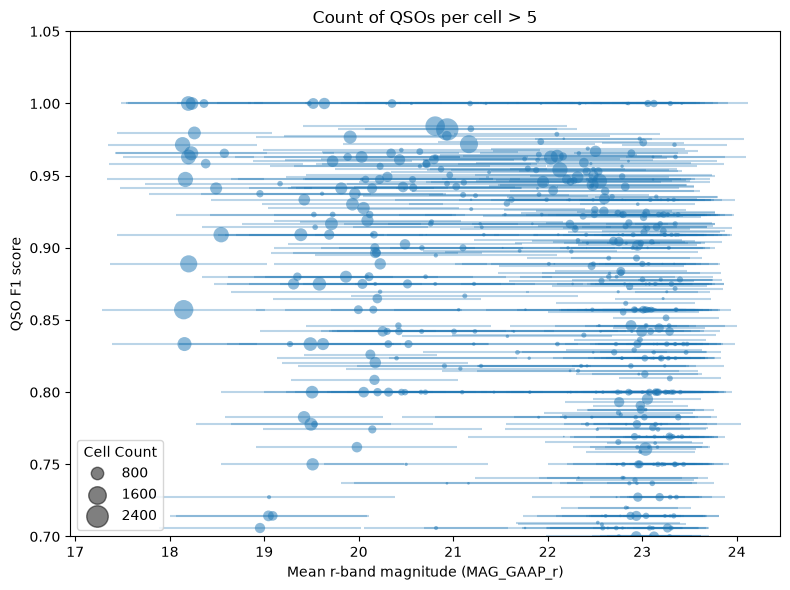

In [19]:
assignments['mag_r'] = training_data.data.loc[training_data.idx_test, 'MAG_GAAP_r'].reset_index(drop=True)
mean_r_per_cell = assignments.groupby('cell_id')['mag_r'].mean()
std_r_per_cell = assignments.groupby('cell_id')['mag_r'].std()

# Total objects per cell (use qso_count_per_cell instead if you want QSO counts specifically)
total_count_per_cell = assignments.groupby('cell_id').size()

min_count = 5
index = qso_count_per_cell.loc[qso_count_per_cell > min_count].index

x = mean_r_per_cell.loc[index]
y = qso_f1_per_cell.loc[index]
xerr = std_r_per_cell.loc[index]
counts = total_count_per_cell.loc[index]

# Scale factor to make marker areas visually readable (adjust as needed)
scale_factor = 0.1 

plt.figure(figsize=(8, 6))

# 1. Plot error bars only (fmt='none' hides the uniform markers)
plt.errorbar(x, y, xerr=xerr, fmt='none', ecolor='C0', alpha=0.3, zorder=1)

# 2. Plot markers with variable sizes using scatter
sc = plt.scatter(x, y, s=counts * scale_factor, color='C0', alpha=0.5, edgecolors='none', zorder=2)

# Optional: Add a legend showing what marker sizes correspond to
handles, labels = sc.legend_elements(prop="sizes", num=4, func=lambda s: s / scale_factor)
plt.legend(handles, labels, title="Cell Count", loc="lower left")

plt.xlabel('Mean r-band magnitude (MAG_GAAP_r)')
plt.ylabel('QSO F1 score')
plt.ylim(bottom=0.7)
plt.title(f'Count of QSOs per cell > {min_count}')
plt.tight_layout()
plt.savefig(f'../figs/som/qso_f1_vs_mean_r_per_cell_min_{min_count}.png', dpi=300)
plt.show()
